# ========================================
# 04A_Embeddings_Clustering.ipynb
# ========================================

Batches:   0%|          | 0/1935 [00:00<?, ?it/s]

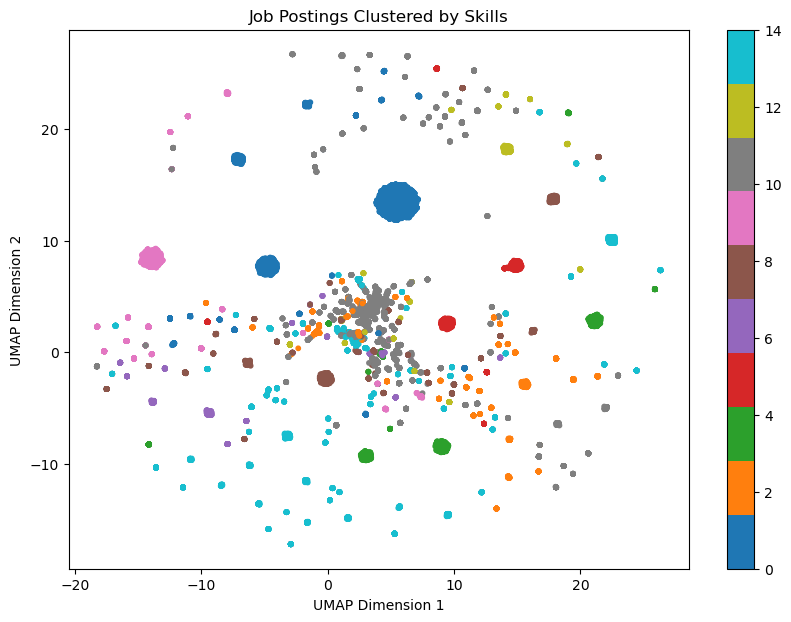


✅ Clustered dataset saved to outputs/extracted_data/final_structured_job_postings_with_clusters.csv


In [3]:


# 1. Imports
import pandas as pd
from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans
import umap
import matplotlib.pyplot as plt

# 2. Load Final Structured Dataset
df = pd.read_csv('/Users/ronitgandhi/Portfolio Projects/job_postings_insights/outputs/extracted_data/final_structured_job_postings.csv')

# 3. Prepare Text for Embedding
df['Skills_Text'] = df['Skills'].astype(str).apply(lambda x: ', '.join(eval(x)) if isinstance(eval(x), list) else x)

# 4. Generate Embeddings
model = SentenceTransformer('all-MiniLM-L6-v2')  # small but strong model

embeddings = model.encode(df['Skills_Text'].tolist(), batch_size=64, show_progress_bar=True)

# 5. Clustering
n_clusters = 10  # you can adjust this
kmeans = KMeans(n_clusters=15, random_state=42)
cluster_labels = kmeans.fit_predict(embeddings)


df['Cluster'] = cluster_labels

# 6. Visualize Clusters in 2D (optional)
reducer = umap.UMAP()
embedding_2d = reducer.fit_transform(embeddings)

plt.figure(figsize=(10, 7))
plt.scatter(embedding_2d[:, 0], embedding_2d[:, 1], c=cluster_labels, cmap='tab10', s=10)
plt.title('Job Postings Clustered by Skills')
plt.xlabel('UMAP Dimension 1')
plt.ylabel('UMAP Dimension 2')
plt.colorbar()
plt.show()

# 7. Save Clustered Data
df.to_csv('/Users/ronitgandhi/Portfolio Projects/job_postings_insights/outputs/extracted_data/final_structured_job_postings_with_clusters.csv', index=False)

print("\n✅ Clustered dataset saved to outputs/extracted_data/final_structured_job_postings_with_clusters.csv")
